## 1-2. Model training and Calculation of metrics

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, accuracy_score, f1_score, log_loss, precision_recall_curve, roc_curve, roc_auc_score)

bioresponce = pd.read_csv("bioresponse.csv", header=0, sep=',')

In [4]:
Y = bioresponce.Activity.values
X = bioresponce.iloc[:, 1:]

In [5]:
models = (DecisionTreeClassifier(max_depth=3, random_state=1),
    DecisionTreeClassifier(max_depth=15, random_state=1),
    RandomForestClassifier(n_estimators=50, max_depth=3, random_state=1),
    RandomForestClassifier(n_estimators=50, max_depth=15, random_state=1)
)

In [6]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.25, random_state=1)

In [7]:
precision = []
recall = []
accuracy = []
f1 = []
logloss = []

probas = [] 

for model in models:
    model.fit(x_train, y_train)

    pred_proba = model.predict_proba(x_test)
    pred = model.predict(x_test)

    precision.append(precision_score(y_test, pred))
    recall.append(recall_score(y_test, pred))
    accuracy.append(accuracy_score(y_test, pred))
    f1.append(f1_score(y_test, pred))
    logloss.append(log_loss(y_test, pred_proba))

    probas.append(pred_proba[:, 1])


## 3. Plot precision-recall and ROC curves 

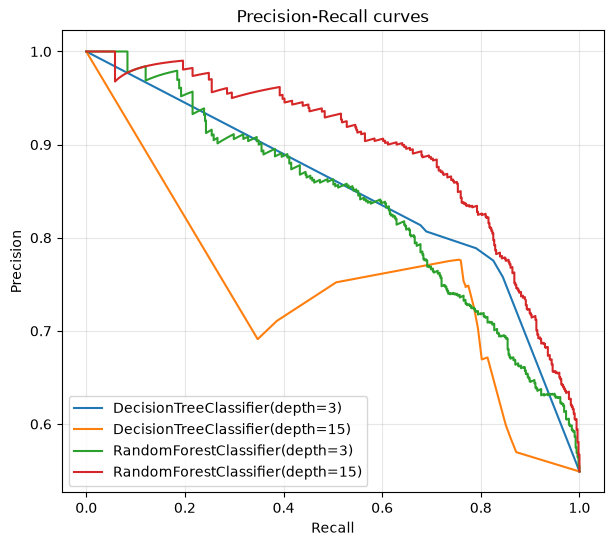

In [8]:
plt.figure(figsize=(7, 6))
for model, proba in zip(models, probas):
    prec, rec, _ = precision_recall_curve(y_test, proba)
    plt.plot(rec, prec, label=f"{type(model).__name__}(depth={model.max_depth})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

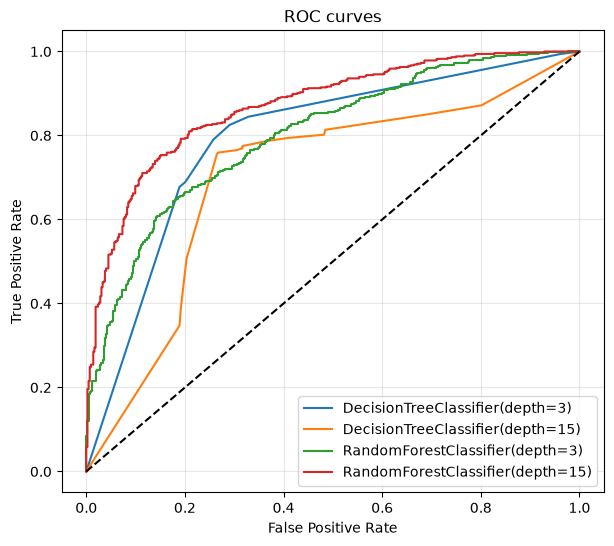

In [9]:
plt.figure(figsize=(7, 6))
for model, proba in zip(models, probas):
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{type(model).__name__}(depth={model.max_depth})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Train a classifier who avoids Type II and Calculation of metrics

In [16]:
best_model = models[3]
y_proba_best = best_model.predict_proba(x_test)[:, 1]

thresholds = np.linspace(0.01, 0.99, 100)
best_thresh = 0.5

for t in thresholds:
    y_pred_t = (y_proba_best > t).astype(int)
    rec = recall_score(y_test, y_pred_t)
    if rec >= 0.95:
        best_thresh = t

y_pred_safe = (y_proba_best > best_thresh).astype(int)

print(f"Выбранный порог T: {best_thresh:.2f}")
print(f"Recall = {recall_score(y_test, y_pred_safe):.3f}")
print(f"Precision = {precision_score(y_test, y_pred_safe):.3f}")
print(f"F1 = {f1_score(y_test, y_pred_safe):.3f}")
print(f"Accuracy = {accuracy_score(y_test, y_pred_safe):.3f}")
print(f"Log-loss = {log_loss(y_test, y_proba_best):.3f}") 

Выбранный порог T: 0.26
Recall = 0.953
Precision = 0.656
F1 = 0.777
Accuracy = 0.699
Log-loss = 0.463
